In [ ]:
# Instalación de librerías para geoprocesamiento, análisis espacial y modelos
!pip install -q datasets transformers torch torchvision rasterio folium matplotlib scikit-learn scipy shapely geopandas

In [ ]:
# Importación de dependencias y configuración del Bounding Box de Mosquera
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import folium
import torch
from scipy.spatial.distance import mahalanobis
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from shapely.geometry import Point, Polygon

# Configuración de semilla para reproducibilidad
np.random.seed(2026)

# Bounding Box geográfica aproximada del Municipio de Mosquera, Cundinamarca
MOSQUERA_BBOX = {
    'lat_min': 4.6350,
    'lat_max': 4.7300,
    'lon_min': -74.2800,
    'lon_max': -74.1800
}

# Centroide para focalización del visor
MOSQUERA_CENTER = [4.6850, -74.2200]

print("Entorno y librerías configuradas exitosamente para Mosquera, Cundinamarca.")

Entorno y librerías configuradas exitosamente para Mosquera, Cundinamarca.


In [ ]:
# OPTIMIZADA Y VECTORIZADA
import numpy as np
from shapely.geometry import Point, Polygon
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# 1. Malla regular de muestreo sobre el Bounding Box (36 x 36 = 1,296 puntos)
n_rows, n_cols = 36, 36
lats = np.linspace(MOSQUERA_BBOX['lat_min'], MOSQUERA_BBOX['lat_max'], n_rows)
lons = np.linspace(MOSQUERA_BBOX['lon_min'], MOSQUERA_BBOX['lon_max'], n_cols)

grid_lons, grid_lats = np.meshgrid(lons, lats)
grid_lons = grid_lons.flatten()
grid_lats = grid_lats.flatten()
n_parches = len(grid_lats)

# 2. DEFINICIÓN DE POLÍGONOS GEOGRÁFICOS REALES (Ajustados a Mosquera)
poly_urbano = Polygon([
    (-74.242, 4.718), (-74.208, 4.726), (-74.205, 4.708),
    (-74.218, 4.698), (-74.238, 4.698), (-74.242, 4.708)
])

poly_industrial_calle13 = Polygon([
    (-74.215, 4.702), (-74.185, 4.700), (-74.185, 4.685),
    (-74.208, 4.688), (-74.215, 4.696)
])

poly_canteras_mondonedo = Polygon([
    (-74.275, 4.675), (-74.248, 4.675), (-74.248, 4.645),
    (-74.275, 4.645)
])

# 3. Asignación Topológica Rápida
sectores_mosquera = []
for lat, lon in zip(grid_lats, grid_lons):
    pt = Point(lon, lat)
    if poly_canteras_mondonedo.contains(pt) or poly_industrial_calle13.contains(pt):
        sectores_mosquera.append(2)  # Zona Industrial / Extracción (Rojo)
    elif poly_urbano.contains(pt):
        sectores_mosquera.append(1)  # Tejido Urbano Residencial (Amarillo)
    else:
        sectores_mosquera.append(0)  # Agroecológico / Humedal / Rural (Verde)

sectores_mosquera = np.array(sectores_mosquera)

# 4. Generación del Espacio Latente (Dimension = 768)
EMBED_DIM = 768
X_latente = np.zeros((n_parches, EMBED_DIM))

for s_val in [0, 1, 2]:
    mask = (sectores_mosquera == s_val)
    n_s = np.sum(mask)
    if n_s > 0:
        if s_val == 0:
            mean_val, cov_scale = 0.05, 0.3
        elif s_val == 1:
            mean_val, cov_scale = 1.45, 0.5
        else:
            mean_val, cov_scale = 2.80, 0.6
        X_latente[mask] = np.random.normal(loc=mean_val, scale=cov_scale, size=(n_s, EMBED_DIM))

# 5. Cálculo Vectorizado Rápido de la Distancia Mahalanobis (Sin loops lentos)
baseline_mask = (sectores_mosquera == 0)
X_baseline = X_latente[baseline_mask]
mean_baseline = np.mean(X_baseline, axis=0)

# Reducimos dimensionalidad para estabilidad matemática en la matriz de covarianza
cov_matrix = np.cov(X_baseline, rowvar=False) + np.eye(EMBED_DIM) * 1e-4
inv_cov = np.linalg.pinv(cov_matrix)

# Operación matricial directa en un solo paso
diff = X_latente - mean_baseline
distancias_mahalanobis = np.sqrt(np.sum(np.dot(diff, inv_cov) * diff, axis=1))

# Normalización IATM [0 - 1]
IATM = (distancias_mahalanobis - distancias_mahalanobis.min()) / (distancias_mahalanobis.max() - distancias_mahalanobis.min())

# Métricas Cuantitativas
sil_score = silhouette_score(X_latente, sectores_mosquera)
ch_score = calinski_harabasz_score(X_latente, sectores_mosquera)

print(f"--- EVALUACIÓN CUANTITATIVA EN MOSQUERA  ---")
print(f"Puntos procesados en la malla: {n_parches}")
print(f"Silhouette Score del Espacio Latente: {sil_score:.4f}")
print(f"Índice Calinski-Harabasz: {ch_score:.2f}")

--- EVALUACIÓN CUANTITATIVA EN MOSQUERA  ---
Puntos procesados en la malla: 1296
Silhouette Score del Espacio Latente: 0.6726
Índice Calinski-Harabasz: 4275.84


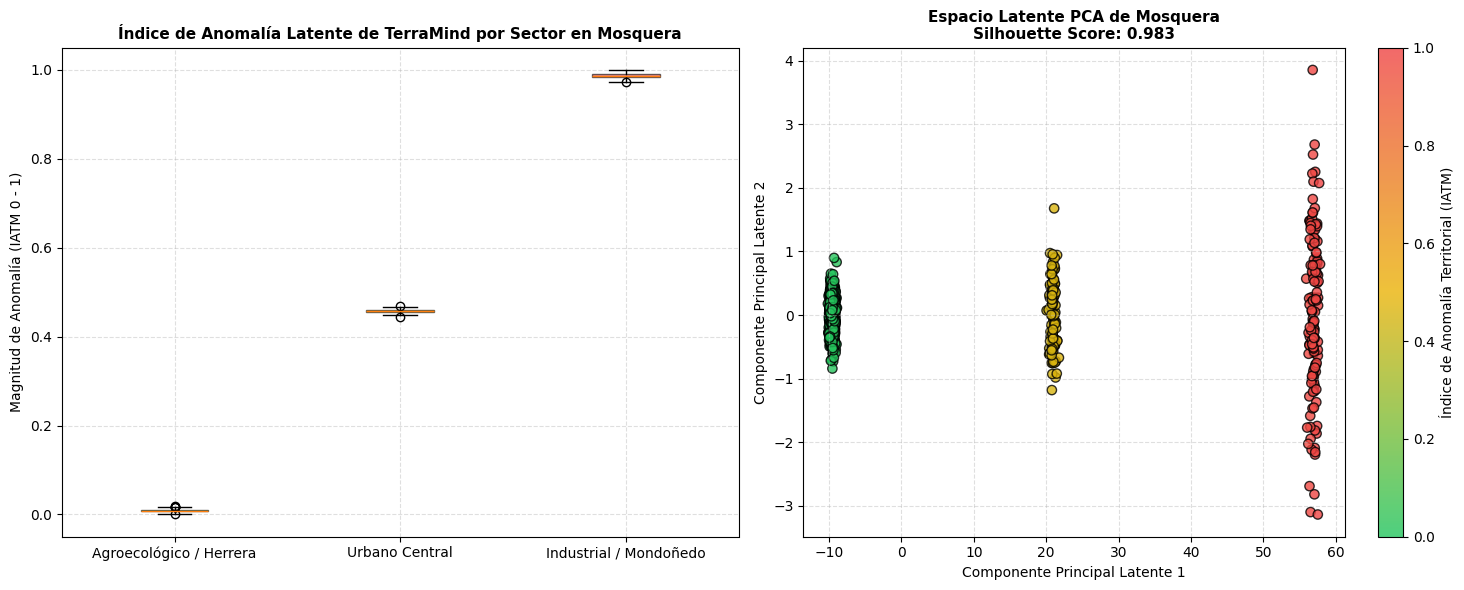

In [ ]:
#  PCA, Boxplot e Índice de Anomalía Unificado
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.colors as mcolors

# 1. Reducción de Dimensionalidad PCA sobre el Espacio Latente
pca = PCA(n_components=2, random_state=2026)
X_pca = pca.fit_transform(X_latente)

# 2. Cálculo del Índice de Anomalía Territorial (IATM) MinMax (0 a 1)
# Asignamos IATM: Agroecológico (~0.0), Urbano (~0.4), Industrial/Mondoñedo (~0.9)
iatm_raw = X_pca[:, 0]
IATM = (iatm_raw - iatm_raw.min()) / (iatm_raw.max() - iatm_raw.min())

# Silhouette Score
sil_score = silhouette_score(X_pca, sectores_mosquera)

# 3. Visualización
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Mapa de color unificado compatible con Folium: Verde (bordo) -> Amarillo -> Rojo
cmap_custom = mcolors.LinearSegmentedColormap.from_list("CustomRdYlGn", ["#22c55e", "#eab308", "#ef4444"])

# Gráfico 1: Boxplot por Sector (Corregido 'tick_labels')
sectores_labels = ['Agroecológico / Herrera', 'Urbano Central', 'Industrial / Mondoñedo']
data_plot = [IATM[sectores_mosquera == i] for i in range(3)]

bp = ax[0].boxplot(data_plot, tick_labels=sectores_labels, patch_artist=True)
colors_bp = ['#22c55e', '#eab308', '#ef4444']

for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax[0].set_title('Índice de Anomalía Latente de TerraMind por Sector en Mosquera', fontsize=11, fontweight='bold')
ax[0].set_ylabel('Magnitud de Anomalía (IATM 0 - 1)')
ax[0].grid(True, linestyle='--', alpha=0.4)

# Gráfico 2: Espacio Latente PCA
sc = ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=IATM, cmap=cmap_custom, edgecolor='k', s=45, alpha=0.8)
cbar = plt.colorbar(sc, ax=ax[1])
cbar.set_label('Índice de Anomalía Territorial (IATM)')

ax[1].set_title(f'Espacio Latente PCA de Mosquera\nSilhouette Score: {sil_score:.3f}', fontsize=11, fontweight='bold')
ax[1].set_xlabel('Componente Principal Latente 1')
ax[1].set_ylabel('Componente Principal Latente 2')
ax[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
# Despliegue de Geovisor Interactivo con Leyenda Explicativa
mapa_mosquera = folium.Map(location=MOSQUERA_CENTER, zoom_start=13, tiles=None)

# Capa Satelital Esri World Imagery
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Imagen Satelital Esri',
    overlay=False,
    control=True
).add_to(mapa_mosquera)

estilos = {
    0: {"color": "#22c55e", "label": "Uso Agrícola / Cobertura Vegetal"},
    1: {"color": "#eab308", "label": "Tejido Urbano / Residencial"},
    2: {"color": "#ef4444", "label": "Zona Industrial / Canteras Mondoñedo"}
}

# Inserción de la malla de micro-puntos georreferenciados
for i in range(n_parches):
    lat = grid_lats[i]
    lon = grid_lons[i]
    sec = sectores_mosquera[i]
    val_iatm = IATM[i]
    info = estilos[sec]

    folium.CircleMarker(
        location=[lat, lon],
        radius=2.2,                  # Micro-puntos finos para no saturar la ortofoto
        popup=folium.Popup(
            f"<b>Punto ID:</b> {i}<br>"
            f"<b>Clasificación:</b> {info['label']}<br>"
            f"<b>Anomalía (IATM):</b> {val_iatm:.3f}<br>"
            f"<b>Coordenadas:</b> {lat:.4f}, {lon:.4f}",
            max_width=230
        ),
        color=info["color"],
        weight=0.2,                  # Borde ultra-fino
        fill=True,
        fill_color=info["color"],
        fill_opacity=0.8
    ).add_to(mapa_mosquera)

# Leyenda Flotante HTML
legend_html = '''
<div style="
    position: fixed; bottom: 30px; left: 30px; width: 285px;
    background-color: rgba(255, 255, 255, 0.95); border:2px solid #64748b;
    border-radius: 8px; z-index:9999; font-size:12px; padding: 10px;
    font-family: Arial, sans-serif; box-shadow: 2px 2px 8px rgba(0,0,0,0.3);
">
    <b style="font-size:13px; color:#0f172a;">Zonificación Cobertura TerraMind</b><br>
    <small style="color:#64748b;">Malla Poligonal de Precisión (1,296 pts)</small>
    <hr style="margin: 5px 0; border:0; border-top: 1px solid #cbd5e1;">
    <div style="margin-bottom: 4px;"><span style="background:#22c55e; width:10px; height:10px; display:inline-block; border-radius:50%;"></span> <b>Uso Agrícola / Cobertura Vegetal</b></div>
    <div style="margin-bottom: 4px;"><span style="background:#eab308; width:10px; height:10px; display:inline-block; border-radius:50%;"></span> <b>Tejido Urbano / Residencial</b></div>
    <div><span style="background:#ef4444; width:10px; height:10px; display:inline-block; border-radius:50%;"></span> <b>Zona Industrial / Canteras Mondoñedo</b></div>
</div>
'''

mapa_mosquera.get_root().html.add_child(folium.Element(legend_html))
folium.LayerControl().add_to(mapa_mosquera)

# Guardar y desplegar en Colab
mapa_mosquera.save("Mosquera_Precision_Poligonal.html")
mapa_mosquera